In [20]:
#Import Libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import re

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

In [21]:
#Download and Read the Dataset

filepath = tf.keras.utils.get_file(
    "timemachine.txt",
    "https://www.gutenberg.org/cache/epub/35/pg35.txt"
)

with open(filepath, "r", encoding="utf-8") as f:
    text = f.read()

print(text[:500])

The Project Gutenberg eBook of The Time Machine
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
before using this eBook.

Tit


In [22]:
#Clean the Text

text = text.lower()

# Keep only lowercase letters and spaces
text = re.sub(r"[^a-z\s]", " ", text)

# Remove extra spaces
text = re.sub(r"\s+", " ", text)

print(text[:500])

the project gutenberg ebook of the time machine this ebook is for the use of anyone anywhere in the united states and most other parts of the world at no cost and with almost no restrictions whatsoever you may copy it give it away or re use it under the terms of the project gutenberg license included with this ebook or online at www gutenberg org if you are not located in the united states you will have to check the laws of the country where you are located before using this ebook title the time


In [23]:
#Tokenization

tokenizer = Tokenizer()

tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

token_list = tokenizer.texts_to_sequences([text])[0]

print("Vocabulary size:", total_words)
print(token_list[:20])

Vocabulary size: 4936
[1, 53, 44, 313, 3, 1, 19, 46, 21, 313, 29, 17, 1, 219, 3, 558, 1161, 7, 1, 267]


In [24]:
#Create Sequences

sequence_length = 10

input_sequences = []

for i in range(sequence_length, len(token_list)):

    sequence = token_list[i-sequence_length:i+1]

    input_sequences.append(sequence)

input_sequences = np.array(input_sequences)

print("Sequence shape:", input_sequences.shape)

Sequence shape: (35928, 11)


In [25]:
#Create X and y

X = input_sequences[:, :-1]

y = input_sequences[:, -1]

y = tf.keras.utils.to_categorical(
    y,
    num_classes=total_words
)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (35928, 10)
y shape: (35928, 4936)


In [40]:
#Build the LSTM Model

from tensorflow.keras.layers import Dropout

model = Sequential([

    Input(shape=(sequence_length,)),

    Embedding(
        input_dim=total_words,
        output_dim=100
    ),

    LSTM(
        256,
        dropout=0.2,
        recurrent_dropout=0.2
    ),

    Dense(
        128,
        activation="relu"
    ),

    Dropout(0.2),

    Dense(
        total_words,
        activation="softmax"
    )
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 10, 100)        │       493,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 256)            │       365,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4936)           │       636,744 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,528,808 (5.83 MB)

 Trainable params: 1,528,808 (5.83 MB)

 Non-trainable params: 0 (0.00 B)

In [41]:
#Compile the Model

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 10, 100)        │       493,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 256)            │       365,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4936)           │       636,744 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,528,808 (5.83 MB)

 Trainable params: 1,528,808 (5.83 MB)

 Non-trainable params: 0 (0.00 B)

In [42]:
#Create Early Stopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [43]:
#Train the LSTM

history = model.fit(
    X,
    y,
    epochs=30,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stopping]
)

Epoch 1/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 56s 205ms/step - accuracy: 0.0668 - loss: 6.6185 - val_accuracy: 0.0646 - val_loss: 7.5372
Epoch 2/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 57s 224ms/step - accuracy: 0.0758 - loss: 6.1910 - val_accuracy: 0.0796 - val_loss: 7.7141
Epoch 3/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 52s 207ms/step - accuracy: 0.0927 - loss: 5.9891 - val_accuracy: 0.0835 - val_loss: 7.8559
Epoch 4/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 50s 197ms/step - accuracy: 0.1021 - loss: 5.8207 - val_accuracy: 0.0863 - val_loss: 7.8388
Epoch 5/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 50s 198ms/step - accuracy: 0.1139 - loss: 5.6841 - val_accuracy: 0.0860 - val_loss: 7.9609
Epoch 6/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 48s 191ms/step - accuracy: 0.1219 - loss: 5.5615 - val_accuracy: 0.0807 - val_loss: 8.0511
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 1.


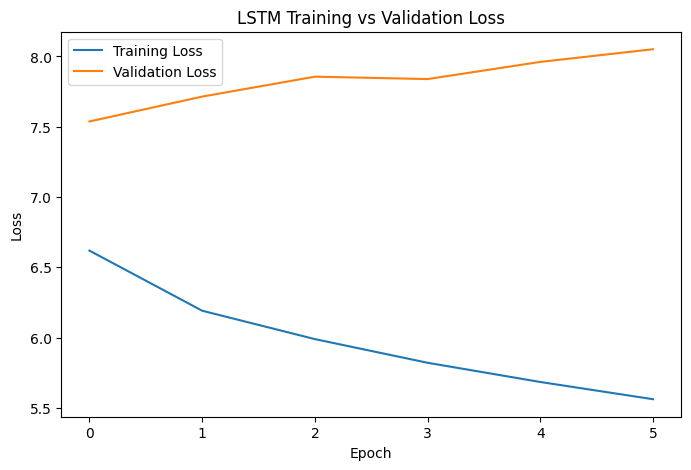

In [44]:
#Plot Loss

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training vs Validation Loss")

plt.legend()
plt.show()

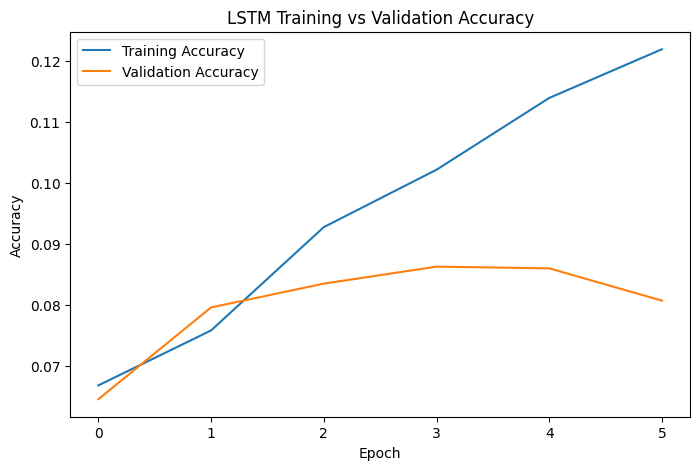

In [45]:
#Plot Training and Validation Accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Training vs Validation Accuracy")

plt.legend()
plt.show()

In [46]:
#Next Word Prediction Function

def predict_next_word(seed_text):

    seed_text = seed_text.lower()

    sequence = tokenizer.texts_to_sequences([seed_text])[0]

    sequence = pad_sequences(
        [sequence],
        maxlen=sequence_length,
        padding="pre"
    )

    prediction = model.predict(
        sequence,
        verbose=0
    )

    predicted_word_index = np.argmax(prediction)

    return tokenizer.index_word.get(
        predicted_word_index,
        ""
    )

In [47]:
#Test the Model

print(predict_next_word("the time traveller"))

the


In [48]:
#Temperature Sampling Function

def sample_with_temperature(predictions, temperature=0.8):

    predictions = np.asarray(predictions).astype("float64")

    predictions = np.log(predictions + 1e-10) / temperature

    exp_predictions = np.exp(predictions)

    probabilities = exp_predictions / np.sum(exp_predictions)

    predicted_index = np.random.choice(
        len(probabilities),
        p=probabilities
    )

    return predicted_index

In [49]:
#Generate Text

def generate_text(
    seed_text,
    num_words,
    temperature=0.8
):

    for _ in range(num_words):

        sequence = tokenizer.texts_to_sequences(
            [seed_text]
        )[0]

        # Keep only the most recent words
        sequence = sequence[-sequence_length:]

        sequence = pad_sequences(
            [sequence],
            maxlen=sequence_length,
            padding="pre"
        )

        prediction = model.predict(
            sequence,
            verbose=0
        )[0]

        predicted_index = sample_with_temperature(
            prediction,
            temperature
        )

        predicted_word = tokenizer.index_word.get(
            predicted_index,
            ""
        )

        if predicted_word == "":
            continue

        seed_text += " " + predicted_word

    return seed_text

In [50]:
#Generate 20 Words

print(
    generate_text(
        "the time traveller",
        20,
        temperature=0.8
    )
)

the time traveller to times set world time to have folly fire a open someone could i must i it people he of


In [51]:
#Save the LSTM Model

model.save("time_machine_lstm.keras")